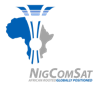 &nbsp;&nbsp; 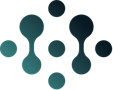

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Publica-AI/nigcomsat-ai-developer/blob/main/Jasons-Restructure/week-5/day-1-honest-splits-and-quiz-3/4-instructor-only/W5D1-solution.ipynb)

> 🧑🏾‍🏫 **INSTRUCTOR SOLUTION.** Every blank is filled in. Don't share this with participants before the session ends.

# 🥊 Week 5 · Day 1: No Expo! Honest Train/Test Splits

**Today:** you catch a model cheating, build an honest split by time, and referee a fair fight between the isolation forest and the Week 4 control chart.

| Symbol | Means |
|---|---|
| 📖 | Read this |
| ▶️ | Run the cell below (click it, then **Shift + Enter**) |
| ✍️ | Your turn: replace every `___` with your answer |
| ✅ / ❌ | The check tells you if you got it right, with a hint if not |
| 🌶️ | Bonus task for fast finishers |

> ## ⚠️ Do this FIRST: **File → Save a copy in Drive**

**Rule book:** keep `W5D1-rulebook.pdf` open next to you.

## ▶️ STEP 0: Set up
Run it once every time you open the notebook (and after every restart). Wait for `✅ Ready!`.

In [ ]:
#@title 🚀 STEP 0 · Run me first (click the ▶ button on the left of this cell) { display-mode: "form" }
import sys, warnings
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold",
                     "axes.prop_cycle": plt.cycler(color=["#0A5DB4", "#C77700", "#008C7E"])})

IN_COLAB = "google.colab" in sys.modules
RAW = "https://raw.githubusercontent.com/Publica-AI/nigcomsat-ai-developer/main/Time-series"
DATA_HOME = {'additive_multiplicative_demo': 'week-03', 'bandwidth_throughput_daily': 'week-03', 'ka_band_availability_daily': 'week-03', 'ka_band_availability_monthly': 'week-03', 'link_margin_hourly_aug2025': 'week-03', 'noc_tickets_daily': 'week-03', 'noc_tickets_weekly': 'week-03', 'transponder_utilisation_monthly': 'week-03', 'vsat_uptime_by_region_weekly': 'week-03', 'rf_link_quality_hourly': 'week-03', 'bus_power_telemetry_hourly': 'week-04', 'battery_health_daily': 'week-04', 'twta_thermal_daily': 'week-04', 'telemetry_anomaly_labels': 'week-04', 'bus_telemetry_multivariate_hourly': 'week-05', 'anomaly_labels_week5': 'week-05', 'degradation_assets_daily': 'week-06', 'degradation_thresholds': 'week-06', 'ops_tickets_weekly': 'week-06'}

def data_path(name, week=None):
    """Download a course CSV once and return where it is saved.
    week: which original folder to use, e.g. "week-03" (two files exist in both week-03 and week-04).
    If you uploaded the file yourself (Files panel), that copy is used instead."""
    uploaded = Path(f"{name}.csv")
    if uploaded.exists():
        return uploaded
    week = week or DATA_HOME[name]
    local = Path("course_data") / week / f"{name}.csv"
    if not local.exists():
        local.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f"{RAW}/{week}/data/{name}.csv", local)
    return local

def load_labels(name="telemetry_anomaly_labels", week=None):
    """Read an answer-key (labels) file. The original telemetry_anomaly_labels.csv has a stray comma
    inside one description, which makes pd.read_csv crash, so the last column is read as free text."""
    lines = Path(data_path(name, week)).read_text(encoding="utf-8").splitlines()
    cols = lines[0].split(",")
    rows = [ln.split(",", len(cols) - 1) for ln in lines[1:] if ln.strip()]
    df = pd.DataFrame(rows, columns=cols)
    for c in ("start", "end"):
        if c in df:
            df[c] = pd.to_datetime(df[c], format="mixed")
    return df

___ = None          # this is "the blank". Replace every ___ with your answer.
SCORE = {}

def _blank(x):
    return x is None or (isinstance(x, tuple) and any(v is None for v in x))

def check(task, answer):
    """Marks one task. Prints ✅ or ❌ with a hint."""
    if _blank(answer):
        print("✍️  Fill in the blank first: replace ___ with your answer, then run the cell again.")
        return
    try:
        ok, good, hint = CHECKS[task](answer)
    except Exception as e:
        ok, good, hint = False, "", f"{HINTS.get(task, 'Read the task again.')}  (Python said: {type(e).__name__})"
    SCORE[task] = ok
    print(("✅ " + good) if ok else ("❌ Not yet. Hint: " + hint))

def scoreboard():
    got = sum(SCORE.values())
    print(f"You have {got} of {len(CHECKS)} tasks correct.")
    print("🏆 Oya, you don finish! Mad o!" if got == len(CHECKS) else "💪 Keep going: scroll up and fix the ❌ ones.")

# ---- today's checks ----
def _near(x, want, tol):
    return abs(float(x) - want) <= tol

def _res(x, caught, fa):
    return isinstance(x, dict) and x.get("caught") == caught and x.get("false_alarms") == fa

def _c_a1(x):
    v = float(x)
    v = v / 100 if v > 1 else v
    return _near(v, 1.0, 0.001), \
        "100% of the fault hours found! An A1. Hold your applause: look at how the hours were split. 🤨", \
        "Share of the fault hours the copycat called a fault: pred[y_te == 1].mean()"

def _c_a2(x):
    v = float(x)
    v = v / 100 if v > 1 else v
    return _near(v, 0.034482758620689655, 0.003), \
        f"{v:.1%}. Same model, same features: the A1 was expo. 😬", \
        "Train on Jan to Aug: CUT is the first day of September, written \"2025-09-01\"."

def _c_a3(x):
    return str(x).strip().upper() == 'EV05', \
        "EV05, a repeat of EV02 (May) that the copycat saw in training. It recognises repeats, not new kinds of fault like EV04.", \
        "Look at the table above: which row says caught = True?"

def _c_b1(x):
    return tuple(int(v) for v in x) == (5832, 2904), \
        "5832 training hours, 2904 test hours, and 1 September left out. The assert passed: no overlap. ✂️", \
        "TRAIN_END = \"2025-09-01\" (hours BEFORE it) and TEST_START = \"2025-09-02\" (hours FROM it)."

def _c_b2(x):
    return int(x) == 24, "24 hours: the embargo must be at least as long as the longest feature window. One day it is. 🪑", \
        "rolling(24) looks back 24 hours, so the gap must be at least that many hours."

def _c_c1(x):
    return _res(x, 2, 50), "Caught both events… with 50 false alarms. Now look at WHEN it flagged EV04 (next cell). 👀", \
        "K is the classic number of standard deviations: 3."

def _c_c2(x):
    return str(x).strip().lower() == "lucky", \
        "Lucky! All 84 EV04 flags were 22:00, 23:00 or 00:00: battery recharge after the eclipse, not the amplifier. 🍀", \
        "Every EV04 flag sits in the 3 hours after the 21:00 eclipse. Did the amplifier cause that?"

def _c_c3(x):
    return _res(x, 1, 1), "Quiet: 1 false alarm. But it caught only EV05: raw channels can't see the amplifier running hot for its drive.", \
        "Use the variable steady (no quotes): CONTEXT = steady"

def _c_c4(x):
    ok = isinstance(x, dict) and x.get("caught") == 2 and 5 <= x.get("false_alarms", -1) <= 70
    fa = x.get("false_alarms") if isinstance(x, dict) else "?"
    return ok, f"Both events caught, with {fa} false alarms. The features gave it eyes; the forest added noise. 🌲", \
        "The false-alarm budget fixed in Week 4 Day 2: 0.5%, written 0.005."

def _c_c5(x):
    return _res(x, 2, 1), "Both events, ONE false alarm (the hour after EV05, battery still recovering). Same features as the forest. 🏆", \
        "K is the classic number of standard deviations: 3."

def _c_c6(x):
    return int(x) == 4, "Number 4: the chart on the lean features. The feature won, not the forest. Recommend the simpler detector. ✅", \
        "Pick the one that catches BOTH events with the fewest false alarms, for the right reason."

def _c_d1(x):
    return int(x[0]) == 24 and list(x[1]) == [1, 23, 1, 1], \
        "Four exams instead of one: the chart's false alarms run [1, 23, 1, 1]. A spread, not one lucky number. 🔁", \
        "Use the same embargo as the main split: 24 hours."

def _c_d2(x):
    return int(x) == 150, "150 instead of 502: with EV04 inside the reference, the fault became part of 'normal'. 🧽", \
        "Fit on every steady hour of the year: DIRTY_FIT = steady"

def _c_bonus(x):
    return _near(x, 0.0035, 1e-9), \
        "0.0035: the smallest budget that catches EV01, EV02 and EV03 in the past. On Sep–Dec: 2 false alarms. Tuned honestly, the forest still doesn't beat the chart's 1. 🌶️🏆", \
        "Read the list: the FIRST budget (smallest) where it catches 3 of 3 past events."

CHECKS = {"A1": _c_a1, "A2": _c_a2, "A3": _c_a3, "B1": _c_b1, "B2": _c_b2, "C1": _c_c1, "C2": _c_c2, "C3": _c_c3,
          "C4": _c_c4, "C5": _c_c5, "C6": _c_c6, "D1": _c_d1, "D2": _c_d2, "BONUS": _c_bonus}
HINTS = {"B1": "Two dates, as text: TRAIN_END and TEST_START.", "D1": "GAP is a number of hours."}

print(f"✅ Ready! pandas {pd.__version__} · running in {'Google Colab' if IN_COLAB else 'Jupyter'}. Scroll down and let's go 🚀")


### ▶️ The data and the answer key
The same year of hourly bus telemetry as Week 4 Days 2 and 3, and its answer key: 5 labelled events.

In [ ]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, TimeSeriesSplit

bus = pd.read_csv(data_path("bus_telemetry_multivariate_hourly"), parse_dates=["timestamp"], index_col="timestamp").asfreq("h")
labels = load_labels("anomaly_labels_week5")
print("hours:", len(bus), "· events:", len(labels))
display(labels[["event_id", "start", "end", "type"]])

### ▶️ Your tools from Week 4 (run both cells)
You built these pieces on Days 2 and 3: the scorer and its event table, steady sunlight, the lean features (4 health channels + `temp_per_drive`), the chart and the forest. Read them once, then run.

In [ ]:
def score_events(flags, labels, tol="1h"):
    """Event-level scoring, the same 4 rules as Week 4 Day 1. flags: a True/False Series with a time index.
    Events that fall outside the hours being scored are skipped."""
    tol = pd.Timedelta(tol)
    n_events, caught, inside_any = 0, 0, pd.Series(False, index=flags.index)
    for _, ev in labels.iterrows():
        window = (flags.index >= ev["start"] - tol) & (flags.index <= ev["end"] + tol)
        if not window.any():
            continue                     # this event is not in the hours being scored
        n_events += 1
        if flags[window].any():          # one flag or many = ONE catch
            caught += 1
        inside_any |= window
    false_alarms = int((flags & ~inside_any).sum())
    alarms = caught + false_alarms
    return {"events": n_events, "caught": caught, "false_alarms": false_alarms,
            "recall": round(caught / n_events, 3) if n_events else float("nan"),
            "precision": round(caught / alarms, 3) if alarms else float("nan")}

def event_table(flags, labels):
    """One row per event: caught? how many hours late was the first flag? how many of its hours lit up?"""
    rows = []
    for _, ev in labels.iterrows():
        inside = (flags.index >= ev["start"]) & (flags.index <= ev["end"])
        if not inside.any():
            continue
        window = (flags.index >= ev["start"] - pd.Timedelta("1h")) & (flags.index <= ev["end"] + pd.Timedelta("1h"))
        hits = flags[window]
        first = hits[hits].index.min() if hits.any() else None
        rows.append({"event": ev["event_id"], "type": ev["type"], "caught": bool(hits.any()),
                     "hours_late": None if first is None else int((first - ev["start"]) / pd.Timedelta("1h")),
                     "hours_flagged": int(flags[inside].sum()), "hours_long": int(inside.sum())})
    return pd.DataFrame(rows).set_index("event").astype({"hours_late": "Int64"})

print("✅ score_events() and event_table() are ready")

In [ ]:
def steady_sun(bus):
    """True in steady sunlight: no eclipse this hour or in the 3 hours before.
    Eclipse (battery power) and the 3 recharge hours after it are normal states with their own normal."""
    return bus["eclipse_flag"].rolling(4).max() == 0

def lean_features(bus):
    """Four health channels plus ONE relationship: amplifier temperature per % of RF drive."""
    X = bus[["solar_array_current_a", "bus_voltage_v", "battery_soc_pct", "battery_temp_c"]].copy()
    X["temp_per_drive"] = bus["twta_temp_c"] / bus["rf_drive_pct"]
    return X

def chart_flags(X, fit_rows, judge_rows, k=3):
    """Week 4 control chart on every column: flag the hour if ANY column is more than k sigma from its normal."""
    ref = X[fit_rows]
    z = (X - ref.mean()) / ref.std()
    return (z.abs() > k).any(axis=1) & judge_rows

def forest_flags(X, fit_rows, judge_rows, contamination=0.005, seed=42):
    """Isolation forest, fitted on the reference rows only, judging the chosen rows."""
    model = IsolationForest(n_estimators=200, contamination=contamination, random_state=seed)
    model.fit(X[fit_rows])
    return pd.Series(model.predict(X) == -1, index=X.index) & judge_rows

steady = steady_sun(bus)
X = lean_features(bus)
print("steady-sun hours:", int(steady.sum()), "· lean features:", list(X.columns))

---
# Part A: Catch the expo (10 min) 🕵🏾

📖 Meet the **copycat**: for each new hour it finds the single most similar hour it has seen, and copies that hour's answer (fault or normal). It **learns from the answer key** (supervised). Our forest never sees labels; the copycat is only here to show how a split can cheat.

▶️ First the answer column `y`: 1 for every hour inside a labelled fault, 0 otherwise.

In [ ]:
y = pd.Series(0, index=bus.index)
for _, ev in labels.iterrows():
    y.loc[ev["start"]:ev["end"]] = 1
print("fault hours in the year:", int(y.sum()))

def copycat():
    """Copies the answer of the ONE most similar hour it has seen (1 nearest neighbour)."""
    return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1))

### A1 ✍️ The random split
The cell shuffles all hours and keeps a third for the test. Then: of the **real fault hours in the test**, what share did the copycat call a fault?
`pred` holds 1 (fault) or 0 (normal) for every test hour, so the share is the mean of `pred` over the fault hours: `pred[y_te == 1].mean()`.

In [ ]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.33, random_state=42)
pred = copycat().fit(X_tr, y_tr).predict(X_te)
print("fault hours in the random test set:", int((y_te == 1).sum()))

found_random = pred[y_te == 1].mean()

assert found_random is not None, "✍️ Fill in found_random first."
print(f"share of fault hours found: {found_random:.1%}")
check("A1", found_random)

### A2 ✍️ Now split by time
Same copycat, same features. This time it trains on **January to August** and is tested on September onwards (skipping one day: Part B explains why).
Type the first day of September as text, like `"2025-01-01"`.

In [ ]:
CUT = "2025-09-01"

assert CUT is not None, "✍️ Fill in CUT first."
before = bus.index < CUT
after = bus.index >= pd.Timestamp(CUT) + pd.Timedelta("1D")
pred_time = pd.Series(copycat().fit(X[before], y[before]).predict(X[after]), index=X.index[after])
found_time = pred_time[y[after] == 1].mean()
print(f"share of fault hours found: {found_time:.1%} (of {int((y[after] == 1).sum())})")
check("A2", found_time)

### A3 ✍️ Which event did it still catch?
▶️ The table shows each test event. Type the event id it caught (e.g. `"EV01"`).

In [ ]:
assert "pred_time" in globals(), "✍️ Finish A2 first, then run this cell."
display(event_table(pred_time == 1, labels))

caught_event = "EV05"

check("A3", caught_event)

> 📖 **What just happened?** In the random split, every test hour inside a fault had its neighbour (one hour earlier or later) in training, and the copycat copied the answer from the next seat. That's **expo**. Split by time, it only recognised EV05, a repeat of EV02 that it had seen in May.

---
# Part B: Split by time (8 min) ✂️

### B1 ✍️ Train, embargo, test
- **train** = every hour **before** 1 September
- **embargo** = 1 September: left out
- **test** = every hour **from** 2 September

Type both dates as text.

In [ ]:
TRAIN_END = "2025-09-01"
TEST_START = "2025-09-02"

assert TRAIN_END is not None and TEST_START is not None, "✍️ Fill in both dates first."
train = bus.index < TRAIN_END
test = bus.index >= TEST_START
print("train hours:", int(train.sum()), "· test hours:", int(test.sum()), "· embargo hours:", int((~train & ~test).sum()))

assert bus.index[train].max() < bus.index[test].min(), "leakage: training overlaps the test"
print("no overlap:", bus.index[train].max(), "<", bus.index[test].min())
check("B1", (train.sum(), test.sum()))

### B2 ✍️ How long must the embargo be?
In Week 4 Day 3 the history features used `rolling(24)`: each value looks back 24 hours. Without a gap, that window on the first test hour would read training hours.
What's the shortest safe embargo, **in hours**?

In [ ]:
EMBARGO_HOURS = 24

check("B2", EMBARGO_HOURS)

---
# Part C: The fair fight (20 min) 🥊

**The rules, written first:** same test months (2 Sep – 31 Dec), same scorer, settings fixed before looking at the test (chart `k = 3`, forest `contamination = 0.005`).

▶️ `on_test()` scores only the test months. Two events live there: **EV04** (the amplifier running hot) and **EV05** (the charge controller).

In [ ]:
def on_test(flags):
    """Score a detector on the held-out months only."""
    return score_events(flags[test], labels)

HEALTH = ["solar_array_current_a", "bus_voltage_v", "battery_soc_pct", "battery_temp_c", "twta_temp_c"]
sunlit = bus["eclipse_flag"] == 0
print("ready: on_test(), HEALTH, sunlit, steady, X")

### C1 ✍️ Contender 1: the Week 4 chart exactly as taught
3σ on each raw health channel, limits from the training months, judging **sunlit** hours (the Week 3 Day 1 fix). Use the classic **K**.

In [ ]:
K = 3

assert K is not None, "✍️ Fill in K first."
flags_1 = chart_flags(bus[HEALTH], train & sunlit, sunlit, k=K)
result_1 = on_test(flags_1)
print(result_1)
check("C1", result_1)

▶️ It caught EV04. But **when** did it flag EV04? Look at the hour of day of every flag inside it.

In [ ]:
assert "flags_1" in globals(), "✍️ Finish C1 first, then run this cell."
display(event_table(flags_1[test], labels))
in_ev04 = flags_1.loc["2025-09-03":"2025-09-30"]
in_ev04[in_ev04].index.hour.value_counts().sort_index().rename_axis("hour of day").to_frame("flags inside EV04")

### C2 ✍️ Real catch or lucky catch?
Eclipse is at 21:00. The 3 hours after it are the battery recharging. EV04 is the **amplifier** running hot. Type `"real"` or `"lucky"`.

In [ ]:
lucky_or_real = "lucky"

check("C2", lucky_or_real)

### C3 ✍️ Contender 2: the same chart on steady sunlight
Recharge hours have their own normal. Fit and judge only **steady** hours instead of sunlit hours. Type the variable name, **no quotes**.

In [ ]:
CONTEXT = steady

assert CONTEXT is not None, "✍️ Fill in CONTEXT first."
assert not isinstance(CONTEXT, str), "✍️ Use the variable itself, without quotes: CONTEXT = steady"
flags_2 = chart_flags(bus[HEALTH], train & CONTEXT, CONTEXT)
result_2 = on_test(flags_2)
print(result_2)
check("C3", result_2)

### C4 ✍️ Contender 3: the isolation forest on the lean features
Steady hours, fitted on the training months. Use the false-alarm budget fixed in Week 4 Day 2: **0.5%**, written as a fraction.

In [ ]:
CONTAMINATION = 0.005

assert CONTAMINATION is not None, "✍️ Fill in CONTAMINATION first."
flags_3 = forest_flags(X, train & steady, steady, contamination=CONTAMINATION)
result_3 = on_test(flags_3)
print(result_3)
check("C4", result_3)

### C5 ✍️ Contender 4: the Week 4 chart on the SAME lean features
Same hours, same months, same features as the forest. Only the model changes.

In [ ]:
K = 3

assert K is not None, "✍️ Fill in K first."
flags_4 = chart_flags(X, train & steady, steady, k=K)
result_4 = on_test(flags_4)
print(result_4)
check("C5", result_4)

▶️ The report card, with one extra column: how many of EV04's hours each detector lit up.

In [ ]:
assert "result_4" in globals(), "✍️ Finish C1–C5 first, then run this cell."
ev04 = (bus.index >= "2025-09-03") & (bus.index < "2025-10-01")
card = pd.DataFrame([
    {"detector": "1. Week 4 chart, raw, sunlit (as taught)", **result_1, "EV04 hours lit": int((flags_1 & ev04).sum())},
    {"detector": "2. Week 4 chart, raw, steady sun", **result_2, "EV04 hours lit": int((flags_2 & ev04).sum())},
    {"detector": "3. Isolation forest, lean features", **result_3, "EV04 hours lit": int((flags_3 & ev04).sum())},
    {"detector": "4. Week 4 chart, lean features", **result_4, "EV04 hours lit": int((flags_4 & ev04).sum())},
]).set_index("detector")
card

### C6 ✍️ Your recommendation
Which detector number (1, 2, 3 or 4) goes on the console? Catching both events **for the right reason** comes first, then the fewest false alarms.

In [ ]:
my_pick = 4

check("C6", my_pick)

---
# Part D: Is it just luck? (7 min) 🔁

### D1 ✍️ Rolling origin: four exams instead of one
`TimeSeriesSplit` cuts the year into blocks. Each fold trains on **everything before** a block and tests on the block. Training only ever grows forwards.
Leave the same embargo between each training block and its test block: how many hours?

In [ ]:
GAP = 24

assert GAP is not None, "✍️ Fill in GAP first."
rows = []
for k, (fit_pos, test_pos) in enumerate(TimeSeriesSplit(n_splits=4, gap=GAP).split(X), start=1):
    fit = np.zeros(len(X), dtype=bool)
    fit[fit_pos] = True
    judge = np.zeros(len(X), dtype=bool)
    judge[test_pos] = True
    c = score_events(chart_flags(X, fit & steady, steady)[judge], labels)
    f = score_events(forest_flags(X, fit & steady, steady)[judge], labels)
    rows.append({"fold": k, "test block": f"{X.index[test_pos[0]]:%d %b} – {X.index[test_pos[-1]]:%d %b}",
                 "chart caught": f"{c['caught']}/{c['events']}", "chart false alarms": c["false_alarms"],
                 "forest caught": f"{f['caught']}/{f['events']}", "forest false alarms": f["false_alarms"]})
folds = pd.DataFrame(rows).set_index("fold")
display(folds)
check("D1", (GAP, folds["chart false alarms"].tolist()))

### D2 ✍️ A dirty reference period
What if you fit on the **whole year**, EV04 included? Set `DIRTY_FIT` to every steady hour of the year (the variable, no quotes). The cell counts how many of EV04's hours each detector still lights up.

In [ ]:
DIRTY_FIT = steady

assert DIRTY_FIT is not None, "✍️ Fill in DIRTY_FIT first."
assert not isinstance(DIRTY_FIT, str), "✍️ Use the variable itself, without quotes: DIRTY_FIT = steady"
lit = pd.DataFrame({
    "clean reference (Jan–Aug)": [int((flags_4 & ev04).sum()), int((flags_3 & ev04).sum())],
    "dirty reference (whole year)": [int((chart_flags(X, DIRTY_FIT, steady) & ev04).sum()),
                                     int((forest_flags(X, DIRTY_FIT, steady) & ev04).sum())],
}, index=["chart", "forest"])
print(f"EV04 hours lit, out of {int(ev04.sum())}:")
display(lit)
check("D2", lit.loc["chart", "dirty reference (whole year)"])

---
## 🌶️ Pepper task: tune the forest the honest way
*"The forest lost because 0.5% was the wrong budget!"* Fair. But you may only tune on the **past**: the training months and their labels (EV01, EV02, EV03). Looking at September to December to choose would be expo.

▶️ The cell tries several budgets on the training months. ✍️ Pick the **smallest** budget that catches all 3 past events, then see what it does on the test.

In [ ]:
assert "result_4" in globals(), "✍️ Finish Part C first, then run this cell."
for c in [0.001, 0.002, 0.0025, 0.003, 0.0035, 0.004, 0.005]:
    r = score_events(forest_flags(X, train & steady, steady, contamination=c)[train], labels)
    print(f"contamination {c:.4f}: caught {r['caught']} of {r['events']} past events, {r['false_alarms']} false alarms")

HONEST_CONTAMINATION = 0.0035

assert HONEST_CONTAMINATION is not None, "✍️ Pick HONEST_CONTAMINATION first."
honest = on_test(forest_flags(X, train & steady, steady, contamination=HONEST_CONTAMINATION))
print("\nforest, honest budget, Sep–Dec:", honest)
print("chart, k = 3, Sep–Dec:          ", result_4)
check("BONUS", HONEST_CONTAMINATION)

---
## 🏁 Finish line
▶️ Run the scoreboard, then **File → Save**.

In [ ]:
scoreboard()

### 📝 What you learned today
- **Expo** fakes a score three ways: test hours with neighbours in training (random splits), features that peek ahead, and settings tuned on the test answers.
- **Split by time:** train on the past, test on the future, with an **embargo** at least as long as your longest feature window, and `assert` there's no overlap.
- **A fair fight** = same held-out months, same hours, same scorer, settings fixed first.
- **Ask why a flag fired.** A catch for the wrong reason is a lucky catch.
- **The feature won, not the forest.** On the same features, the Week 4 chart caught both events with 1 false alarm; the forest needed 25. When the simple model wins or ties, recommend it.
- **One cut is one number.** Rolling origin gives a spread. And a reference period that contains the fault teaches the model that the fault is normal.

**Next time:** *Forecasting baselines*: Grandma's forecast, "tomorrow will be like today", and why she's hard to beat. 👵🏾

<sub>Data: synthetic teaching dataset from the original Week 5 code book (`Time-series/week-05`). Safe to use with AI tools; real NIGCOMSAT data is not.</sub>